# 📓 Notebook 02: Dataset Visualisation

In this notebook, we visualize:
1. The 9-point screen calibration grid where participants looked.
2. The relationship between eye iris movement and screen targets.
3. Head pose variation (yaw, pitch, roll) across different users.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LAB_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = LAB_DIR / "data" / "raw"

df = pd.read_csv(DATA_RAW / "mpiigaze_sample_features.csv")
print(f"Loaded {len(df)} samples.")


Loaded 1350 samples.


---
### Step 1: Visualizing the Screen Target Grid
Here are the target locations on the screen that participants looked at during calibration.


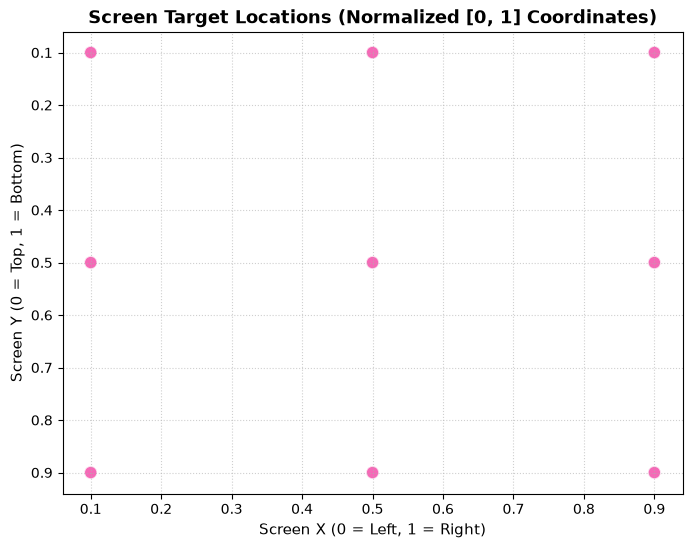

In [2]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, x="target_norm_x", y="target_norm_y", 
    hue="subject", alpha=0.6, s=80, legend=False
)
plt.title("Screen Target Locations (Normalized [0, 1] Coordinates)", fontsize=13, fontweight="bold")
plt.xlabel("Screen X (0 = Left, 1 = Right)", fontsize=11)
plt.ylabel("Screen Y (0 = Top, 1 = Bottom)", fontsize=11)
plt.gca().invert_yaxis()  # Screen coordinates have (0,0) at top-left
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()


---
### Step 2: The Core Eye-Tracking Relationship
Does horizontal iris movement (`dAvgX`) correlate with the target horizontal screen position (`target_norm_x`)?
Let's plot the correlation!


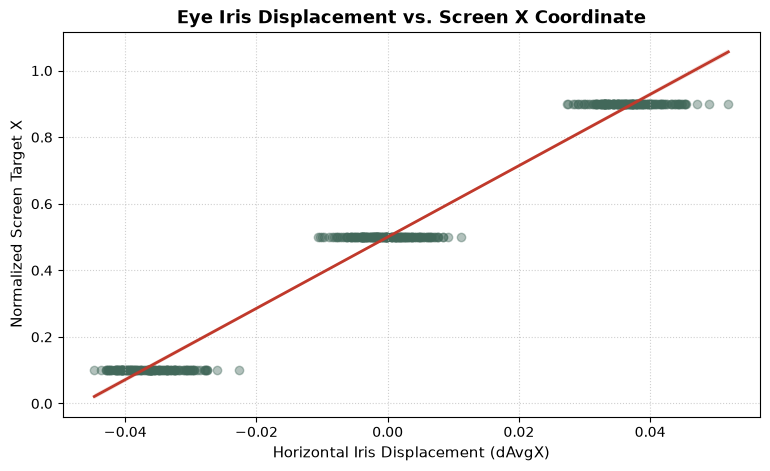

📊 Pearson Correlation Coefficient: 0.989 (Strong positive signal)


In [3]:
plt.figure(figsize=(9, 5))
sns.regplot(data=df.sample(500, random_state=42), x="dAvgX", y="target_norm_x",
            scatter_kws={"alpha": 0.4, "color": "#42685A"}, line_kws={"color": "#C0392B", "linewidth": 2})
plt.title("Eye Iris Displacement vs. Screen X Coordinate", fontsize=13, fontweight="bold")
plt.xlabel("Horizontal Iris Displacement (dAvgX)", fontsize=11)
plt.ylabel("Normalized Screen Target X", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

corr = df['dAvgX'].corr(df['target_norm_x'])
print(f"📊 Pearson Correlation Coefficient: {corr:.3f} (Strong positive signal)")
